# Aragorn Pathfinder: where do the passing assets rank?

This notebook uses the saved **TEST run from November 7, 2026** (17 cases, 79 assets). It sends no queries and publishes nothing.

An asset can match several paths. **First matching rank** is the 1-based position of the earliest analysis satisfying the asset's expected-node threshold, in the server's original order. Rank 1 is best. We do not re-sort scores, and tied scores retain their returned positions.

We reproduce the harness's node-presence check on the first result, using its saved normalized IDs. This checks expected nodes, not correctness of every relationship. The main table focuses on the **26 passing assets**, not all 79 assets. Multiple assets may share a query or a matching path.


Outputs are already saved. To rerun in VS Code, select the repository interpreter `.local/TestHarness/.venv/bin/python` as the notebook kernel. The notebook requires the saved `test_results` folder; it does not download data.

**Folder guide:** notebook outputs go to `../exports/ranks/`. Shared generated data is in `../data/`, and editable reference pathways are in `../references/`. See `../START_HERE.txt` for the reading and execution order.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the repository whether Jupyter starts here or at the repository root.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "test_results/pathfinder-test-full-20261107T192900Z").is_dir())
RUN = ROOT / "test_results/pathfinder-test-full-20261107T192900Z"
BASE = ROOT / "pathfiner_aragorn_exp"
DATA = BASE / "data"
REFERENCES = BASE / "references"
OUT = BASE / "exports/ranks"
OUT.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)
report_file = next((RUN / "reports").glob("*pathfinder_tests*.csv"))
report = pd.read_csv(report_file)
statuses = report.set_index(["TestCase", "TestAsset"])["shepherd-aragorn"].to_dict()
assert len(report) == 79
assert (report["shepherd-aragorn"] == "PASSED").sum() == 26
print(f"Saved run: {RUN.name}; {len(report)} assets, 26 passed.")


Saved run: pathfinder-test-full-20261107T192900Z; 79 assets, 26 passed.


## Find the matching paths

For each asset, inspect every path binding in each analysis. A match requires the configured minimum number of expected nodes **on the same bound path**. The matching logic below follows `pathfinder_test_runner.py`, including alternative identifiers. All matches are retained; the first determines the asset's rank.


In [2]:
def binding_ids(binding):
    return binding.get("ids", []) if isinstance(binding, dict) else [b["id"] for b in binding]


def matching_nodes(edge_ids, edges, expected_groups):
    # Same iteration and alternative-ID handling as TestHarness.
    matched = set()
    for edge_id in edge_ids:
        edge = edges[edge_id]
        for alternatives in expected_groups:
            if not any(curie in matched for curie in alternatives):
                if edge["subject"] in alternatives:
                    matched.add(edge["subject"])
                if edge["object"] in alternatives:
                    matched.add(edge["object"])
    return matched


rows = []
for case_file in sorted(RUN.glob("TestCase_*/assets.json")):
    case_id = case_file.parent.name
    normalized = json.loads((case_file.parent / "normalized_curies.json").read_text())
    # Only cache this case's response(s), avoiding holding the entire run in RAM.
    responses = {}
    for entry in json.loads(case_file.read_text()):
        asset = entry["asset"]
        relative = entry["query_directory"]
        if relative not in responses:
            responses[relative] = json.loads((RUN / relative / "response.json").read_text())
        message = responses[relative]["message"]
        results = message.get("results") or []
        analyses = results[0].get("analyses", []) if results else []
        edges = message["knowledge_graph"]["edges"]
        graphs = message.get("auxiliary_graphs") or {}
        groups = [[normalized[node_id] for node_id in node["ids"]]
                  for node in asset["path_nodes"]]
        hits = []
        for rank, analysis in enumerate(analyses, start=1):
            matches = []
            for binding in (analysis.get("path_bindings") or {}).values():
                for graph_id in binding_ids(binding):
                    matched = matching_nodes(graphs[graph_id]["edges"], edges, groups)
                    if len(matched) >= asset["minimum_required_path_nodes"]:
                        matches.append({"graph_id": graph_id, "nodes": sorted(matched)})
            if matches:
                hits.append({"rank": rank, "score": analysis.get("score"), "matches": matches})
        status = statuses[(case_id, asset["id"])]
        assert bool(hits) == (status == "PASSED"), (case_id, asset["id"], status)
        first = hits[0] if hits else {}
        rows.append({
            "case_id": case_id, "asset_id": asset["id"], "asset": asset["name"],
            "query": f'{asset["source_input_name"]} → {asset["target_input_name"]}',
            "expected_nodes": "; ".join(n.get("name") or "/".join(n["ids"]) for n in asset["path_nodes"]),
            "minimum_required": asset["minimum_required_path_nodes"], "status": status,
            "first_matching_rank": first.get("rank"), "first_matching_score": first.get("score"),
            "matching_path_count": len(hits), "all_matching_ranks": [h["rank"] for h in hits],
            "returned_analyses": len(analyses), "matching_paths": hits,
            "response_file": str(Path("test_results") / RUN.name / relative / "response.json"),
        })
all_assets = pd.DataFrame(rows)
passed = all_assets[all_assets.status == "PASSED"].copy()
passed["first_matching_rank"] = passed["first_matching_rank"].astype(int)
passed = passed.sort_values(["first_matching_rank", "case_id", "asset_id"]).reset_index(drop=True)
assert len(passed) == 26
print("Recomputed matches agree with all 79 official asset results.")


Recomputed matches agree with all 79 official asset results.


## Ranking of the 26 passing assets

`matching_path_count` counts analyses with at least one qualifying path binding. `first_matching_score` is the server's score for the first match; it is not a probability of biological correctness.


In [3]:
columns = ["asset_id", "query", "expected_nodes", "minimum_required",
           "first_matching_rank", "first_matching_score", "matching_path_count"]
with pd.option_context("display.max_rows", 30, "display.max_colwidth", 90):
    display(passed[columns].style.format({"first_matching_score": "{:.4f}"}))


,asset_id,query,expected_nodes,minimum_required,first_matching_rank,first_matching_score,matching_path_count
0,Asset_2,Imatinib → Asthma,KIT,1,2,0.9858,5
1,Asset_23,Crohn's Disease → Parkinson's Disease,LRRK2,1,2,0.9899,58
2,Asset_37,IFNG → tryptophan,IDO1,1,3,0.9623,50
3,Asset_79,Parkinson's Disease → melanoma,LRRK2,1,4,0.9410,28
4,Asset_86,Parkinson's Disease → melanoma,MC1R,1,21,0.8840,5
5,Asset_40,IFNG → tryptophan,T Cell,1,21,0.9168,7
6,Asset_5,Imatinib → Asthma,Mast Cell,1,22,0.9708,5
7,Asset_25,SLC6A20 → COVID-19,ACE2,1,27,0.8830,23
8,Asset_22,Crohn's Disease → Parkinson's Disease,PARK7,1,27,0.9827,15
9,Asset_83,Parkinson's Disease → melanoma,HTRA2,1,28,0.8634,1


In [4]:
ranks = passed["first_matching_rank"]
display(pd.DataFrame({
    "metric": ["Passing assets", "Best first-match rank", "Median first-match rank", "Worst first-match rank"],
    "value": [len(passed), ranks.min(), ranks.median(), ranks.max()],
}))
top_k = pd.DataFrame({"top_k": [1, 5, 10, 20, 50, 100, 500]})
top_k["passing_assets_found"] = [int((ranks <= k).sum()) for k in top_k.top_k]
top_k["percent_of_26_passes"] = (100 * top_k.passing_assets_found / len(passed)).round(1)
display(top_k)
print("These percentages use only the 26 passes. The other 53 assets had no qualifying returned path.")


,metric,value
0,Passing assets,26.0
1,Best first-match rank,2.0
2,Median first-match rank,41.0
3,Worst first-match rank,444.0


,top_k,passing_assets_found,percent_of_26_passes
0,1,0,0.0
1,5,4,15.4
2,10,4,15.4
3,20,4,15.4
4,50,15,57.7
5,100,16,61.5
6,500,26,100.0


These percentages use only the 26 passes. The other 53 assets had no qualifying returned path.


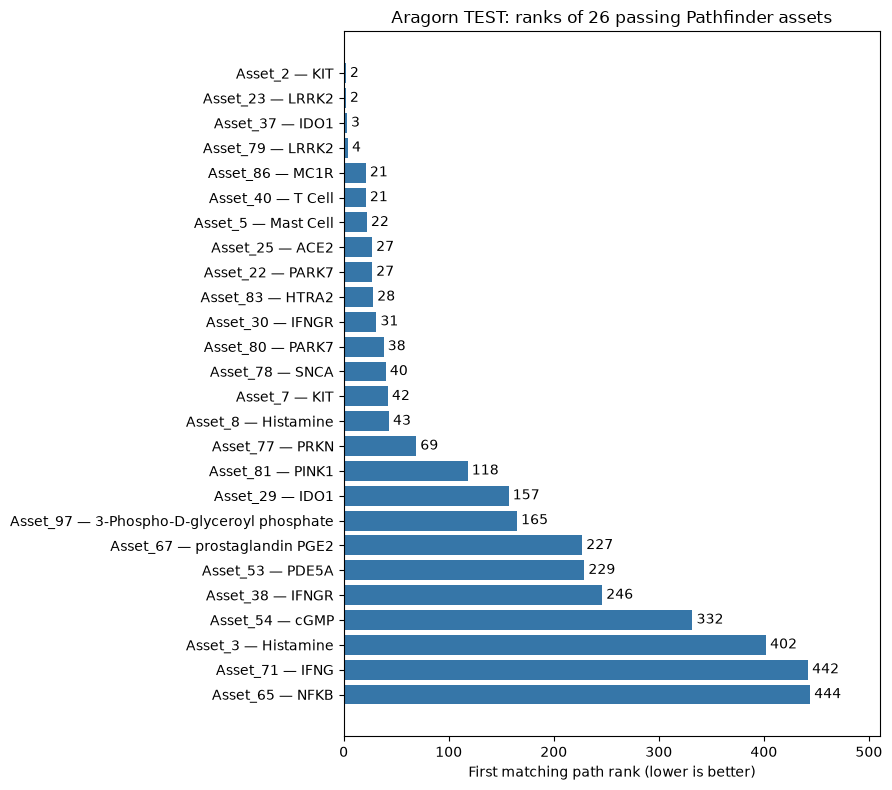

In [5]:
fig, ax = plt.subplots(figsize=(9, 8))
labels = passed["asset_id"] + " — " + passed["expected_nodes"].str.slice(0, 45)
ax.barh(labels, passed["first_matching_rank"], color="#3676a8")
ax.invert_yaxis()
ax.set_xlabel("First matching path rank (lower is better)")
ax.set_title("Aragorn TEST: ranks of 26 passing Pathfinder assets")
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlim(0, passed.first_matching_rank.max() * 1.15)
fig.tight_layout()
fig.savefig(OUT / "passing_asset_ranks.png", dpi=180, bbox_inches="tight")
plt.show()


## Inspect an asset and export the results

Change `asset_id` below to see all its matching ranks and the corresponding path-graph IDs. The linked response file preserves the complete evidence graphs. CSV exports go to `../exports/ranks/`; the shared JSON goes to `../data/`.


In [6]:
asset_id = "Asset_2"  # Imatinib → asthma through KIT
selected = passed.loc[passed.asset_id == asset_id].iloc[0]
print(selected["asset"])
print("Matching ranks:", selected["all_matching_ranks"])
print("Full response:", ROOT / selected["response_file"])
display(pd.DataFrame(selected["matching_paths"]))

export_columns = [c for c in passed.columns if c != "matching_paths"]
passed[export_columns].to_csv(OUT / "passing_asset_ranks.csv", index=False)
passed.to_json(DATA / "passing_asset_ranks.json", orient="records", indent=2)
all_assets.drop(columns="matching_paths").to_csv(OUT / "all_asset_rank_checks.csv", index=False)
print("Saved passing_asset_ranks.csv, passing_asset_ranks.json, all_asset_rank_checks.csv, and the PNG chart.")


PTFQ_1a.1: Imatinib to Asthma, through KIT
Matching ranks: [2, 28, 44, 126, 167]
Full response: /Users/carolinagonzalez/shepherd-new-pathfinder/test_results/pathfinder-test-full-20261107T192900Z/TestCase_0/query-3bb87fb75ea2/response.json


,rank,score,matches
0,2,0.985832,"[{'graph_id': 'p_415', 'nodes': ['NCBIGene:381..."
1,28,0.964051,"[{'graph_id': 'p_8304', 'nodes': ['NCBIGene:38..."
2,44,0.957412,"[{'graph_id': 'p_8418', 'nodes': ['NCBIGene:38..."
3,126,0.931103,"[{'graph_id': 'p_4190', 'nodes': ['NCBIGene:38..."
4,167,0.912619,"[{'graph_id': 'p_9067', 'nodes': ['NCBIGene:38..."


Saved passing_asset_ranks.csv, passing_asset_ranks.json, all_asset_rank_checks.csv, and the PNG chart.
